In [1]:

!pip -q install datasets huggingface_hub scikit-learn seaborn tqdm

import os
import json
import time
import zipfile
import hashlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from huggingface_hub import hf_hub_download

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cuda


In [2]:

zip_path = hf_hub_download(
    repo_id="uqtwei2/PlantWild",
    filename="plantwild.zip",
    repo_type="dataset"
)

extract_path = "/content/PlantWild"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

base_path = "/content/PlantWild/plantwild"
image_dir = os.path.join(base_path, "images")

print("PlantWild extracted successfully!")


plantwild.zip: reconstructing file:   0%|          |  0.00B / 2.71GB            

plantwild.zip: downloading bytes:           |  0.00B            

PlantWild extracted successfully!


In [3]:

# Load class names
class_names = {}

with open(os.path.join(base_path, "classes.txt")) as f:
    for line in f:
        class_id, class_name = line.strip().split(" ", 1)
        class_names[int(class_id)] = class_name

# Read annotations
records = []

with open(os.path.join(base_path, "trainval.txt")) as f:
    for line in f:
        image_path, class_id, flag = line.strip().rsplit("=", 2)

        records.append({
            "image_path": os.path.join(image_dir, image_path),
            "class_id": int(class_id),
            "class_name": class_names[int(class_id)],
            "flag": int(flag)
        })

df = pd.DataFrame(records)

# Official PlantWild splits
train_df = df[df["flag"] == 1].reset_index(drop=True)
val_df = df[df["flag"] == 2].reset_index(drop=True)
test_df = df[df["flag"] == 0].reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Classes:", len(class_names))


Training: 13045
Validation: 1820
Testing: 3677
Classes: 89


In [8]:

import hashlib
import pandas as pd
from tqdm.auto import tqdm

# Create a fresh copy
df_clean = df.copy()

# Calculate exact image hashes
def file_hash(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()

df_clean["hash"] = [
    file_hash(path)
    for path in tqdm(df_clean["image_path"])
]

# Check whether identical images have conflicting labels
conflicts = df_clean.groupby("hash")["class_id"].nunique()
conflicting_hashes = conflicts[conflicts > 1].index

print("Hashes with conflicting labels:",
      len(conflicting_hashes))

# Remove conflicting-label images from all splits
df_clean = df_clean[
    ~df_clean["hash"].isin(conflicting_hashes)
].copy()

# Priority: test (0), validation (2), training (1)
priority = {0: 0, 2: 1, 1: 2}

df_clean["priority"] = df_clean["flag"].map(priority)

df_clean = df_clean.sort_values("priority")

# Keep only one occurrence of each exact image
df_clean = df_clean.drop_duplicates(
    subset="hash",
    keep="first"
)

# Restore original ordering
df_clean = df_clean.sort_index()

# Rebuild official splits
train_df = df_clean[
    df_clean["flag"] == 1
].reset_index(drop=True)

val_df = df_clean[
    df_clean["flag"] == 2
].reset_index(drop=True)

test_df = df_clean[
    df_clean["flag"] == 0
].reset_index(drop=True)

print("\nAfter duplicate removal:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(df_clean))

# Verify no exact duplicates remain across splits
assert not df_clean["hash"].duplicated().any()

print("\nDuplicate removal successful!")



  0%|          | 0/18542 [00:00<?, ?it/s]

Hashes with conflicting labels: 279

After duplicate removal:
Training: 12573
Validation: 1757
Testing: 3566
Total: 17896

Duplicate removal successful!


In [13]:

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class PlantWildDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        label = int(row["class_id"])
        return self.transform(image), label

train_loader = DataLoader(
    PlantWildDataset(train_df, train_transform),
    batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    PlantWildDataset(val_df, eval_transform),
    batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    PlantWildDataset(test_df, eval_transform),
    batch_size=32, shuffle=False, num_workers=2
)

images, labels = next(iter(train_loader))
print("Image shape:", images.shape)
print("Label shape:", labels.shape)


Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])


In [14]:

class PlantDiseaseCNN(nn.Module):

    def __init__(self, num_classes=89):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

print("Custom CNN defined!")


Custom CNN defined!


In [15]:

model = PlantDiseaseCNN(num_classes=89).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 20

print("Model initialized on:", device)


Model initialized on: cuda


In [19]:

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_loss = float("inf")
start_time = time.time()

for epoch in range(epochs):

    # Training
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch+1}/{epochs}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += labels.size(0)

    # Validation
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            val_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total
    val_loss /= val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "custom_cnn_best.pth"
        )

training_time = time.time() - start_time
print(f"Training completed in {training_time/60:.2f} minutes")



Epoch 1/20:   0%|          | 0/393 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 2. 
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d00a807f740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d00a807f740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._

Epoch 1/20 | Train Loss: 3.1828 | Train Acc: 0.2112 | Val Loss: 3.2269 | Val Acc: 0.2203


Epoch 2/20:   0%|          | 0/393 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d00a807f740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d00a807f740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 2/20 | Train Loss: 3.1485 | Train Acc: 0.2188 | Val Loss: 3.1947 | Val Acc: 0.2225


... (50 outputs left out)

Epoch 19/20 | Train Loss: 2.7841 | Train Acc: 0.2889 | Val Loss: 3.0085 | Val Acc: 0.2618


Epoch 20/20:   0%|          | 0/393 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d00a807f740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d00a807f740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 20/20 | Train Loss: 2.7681 | Train Acc: 0.2843 | Val Loss: 3.0124 | Val Acc: 0.2698
Training completed in 50.15 minutes


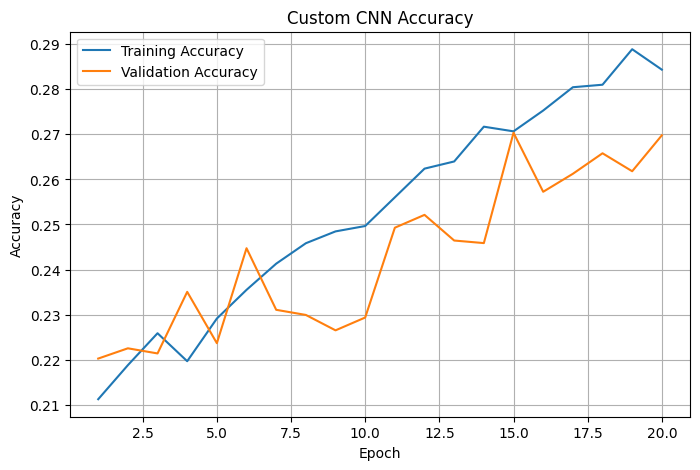

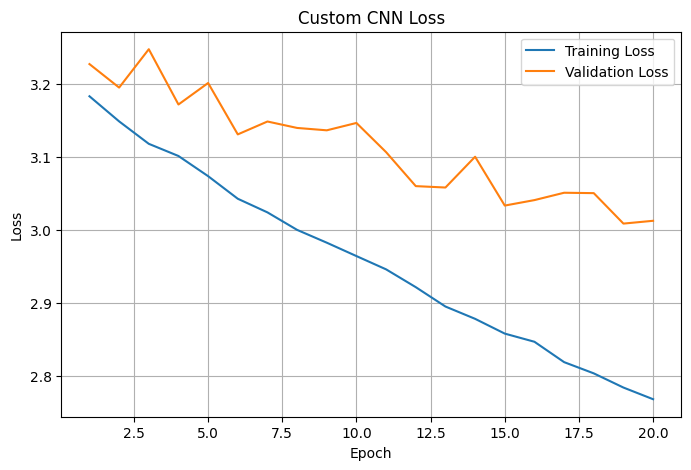

In [20]:


epochs_range = range(1, len(history["train_acc"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_acc"],
         label="Training Accuracy")
plt.plot(epochs_range, history["val_acc"],
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Custom CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_loss"],
         label="Training Loss")
plt.plot(epochs_range, history["val_loss"],
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN Loss")
plt.legend()
plt.grid(True)
plt.show()



  0%|          | 0/112 [00:00<?, ?it/s]

Custom CNN Test Results
Accuracy:  0.2762
Precision: 0.2623
Recall:    0.2247
F1-score:  0.2112


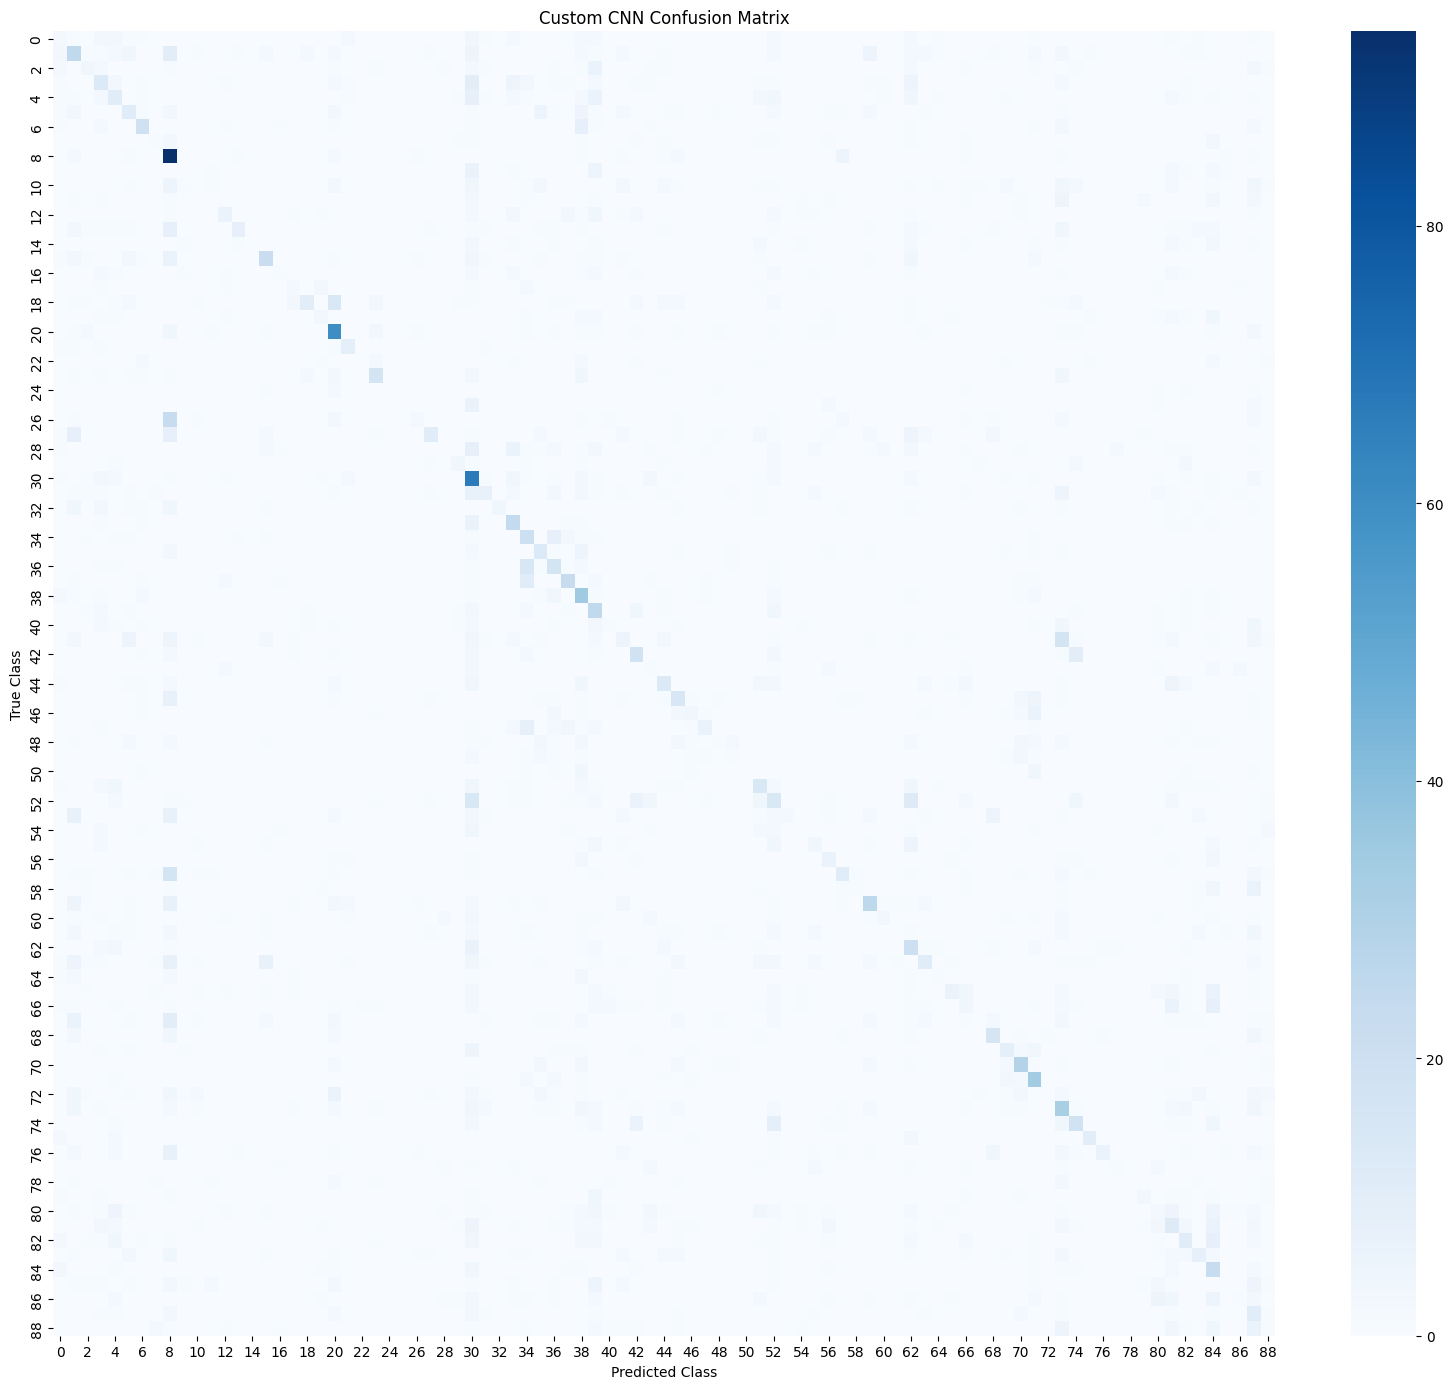

Model and results saved!


In [22]:

# Load best checkpoint
model.load_state_dict(
    torch.load(
        "custom_cnn_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("Custom CNN Test Results")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=list(range(89))
)

plt.figure(figsize=(16, 14))
sns.heatmap(cm, cmap="Blues")
plt.title("Custom CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

# Save class names for the future UI
ordered_classes = [
    class_names[i] for i in range(89)
]

with open("class_names.json", "w") as f:
    json.dump(ordered_classes, f, indent=2)

# Save metrics
metrics = {
    "accuracy": accuracy,
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": f1,
    "training_seconds": training_time
}

with open("custom_cnn_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Model and results saved!")
